# 01b Preprocess the indicators: routes, neighbouring countries and conflicts

**Purpose:** Load and check the three indicators we use next to the series' own past, state what is known at the cutoff, and explore each one before the test period: the **detections on the routes towards Switzerland** (Frontex, sections 1 to 6), the **asylum applications in Germany, Austria, France and Italy** (Eurostat, sections 7 to 10) and a **conflict index** for the nationalities that come to Switzerland (violent events in the news coded by GDELT, weighted by Eurostat's applications by citizenship, sections 11 to 15).
**Input:** `../data/raw/frontex_detections_by_route_monthly.csv`, `../data/raw/estat_migr_asyappctzm_neighbours_en.csv`, `../data/raw/estat_migr_asyappctzm_ch_by_citizenship_en.csv`, `../data/raw/gdelt_events_by_country_month.csv` and `../data/processed/asylum_clean.csv`.
**Output:** `routes_clean.csv`, `neighbours_clean.csv`, `nationality_shares_clean.csv` and `conflict_intensity_clean.csv` in `../data/processed/`, and three figures in `../output/figures/`.

**Which indicators?** Data from one source with one definition, published before our cutoff in **every** month. The routes and the neighbours are known up to month $t-1$ at a forecast origin $t$; GDELT is coded from the news every day and never revised, so the whole month $t$ is known. We looked at two more sources and did not keep them: UNHCR's monthly arrivals (the same numbers as Frontex one month earlier, but their series start only in 2014 to 2018) and UCDP's conflict deaths (final, revised numbers that nobody had at the time, ending in December 2025).

The test period (2024-10 to 2026-09) is only described, never used to choose anything.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the raw data

Frontex publishes the number of **detections of illegal border-crossings** at the external borders of the EU and the Schengen countries, every month, by route. We aggregated the published file (one row per route and nationality) to one column per route; `SOURCES.md` says how, and gives the totals we checked.

**Careful with the meaning:** Frontex counts *detections*, not persons. The same person can be detected several times, for example once on the Eastern Mediterranean route and again on the Western Balkan route. The numbers are an indicator of movement towards Europe, not a count of people.

In [2]:
routes = pd.read_csv("../data/raw/frontex_detections_by_route_monthly.csv")
routes["month"] = pd.to_datetime(routes["month"], format="%Y-%m")
routes = routes.set_index("month")

print("Number of months:", routes.shape[0])
print("First month:", routes.index[0])
print("Last month: ", routes.index[-1])
routes.head()

Number of months: 213
First month: 2009-01-01 00:00:00
Last month:  2026-09-01 00:00:00


,eastern_mediterranean,central_mediterranean,western_mediterranean,western_african,western_balkan,eastern_borders,circular_route_from_albania_to_greece,black_sea,other
month,,,,,,,,,
2009-01-01,2730,1491,508,361,177,93,1521,0,0
2009-02-01,2228,1221,302,685,327,82,1884,1,0
2009-03-01,2870,2519,656,392,355,133,2368,0,1
2009-04-01,3298,1981,423,0,161,112,4207,0,0
2009-05-01,3750,610,557,0,214,115,5512,0,0


## 2. Check the data

The same checks as in `01_preprocess.ipynb` (notebooks 04 and 106): missing values, missing months, and values of zero (the logarithm of 0 does not exist).

In [3]:
first, last = routes.index[0], routes.index[-1]
n_expected = 12 * (last.year - first.year) + (last.month - first.month) + 1
print("Expected number of months:", n_expected, "| in the data:", routes.shape[0])
print("Missing values:", routes.isna().sum().sum())
print()
print("Number of months with zero detections, per route:")
print((routes == 0).sum())

Expected number of months: 213 | in the data: 213
Missing values: 0

Number of months with zero detections, per route:
eastern_mediterranean                      0
central_mediterranean                      1
western_mediterranean                      0
western_african                           29
western_balkan                             0
eastern_borders                            0
circular_route_from_albania_to_greece      0
black_sea                                182
other                                    179
dtype: int64


**What we see.** The file has 213 months (January 2009 to September 2026), no missing value and no missing month. Some routes have months with zero detections: Central Mediterranean once, Western African 29 times, and the two small routes (Black Sea, Other) in most months. The three routes we use, apart from the single zero on the Central Mediterranean, never have a month with zero detections.

## 3. One indicator: the three routes towards Switzerland

We decided **before looking at any relationship with Swiss applications** (so that the choice cannot be fitted to the data, notebook 211) to use one indicator series: the sum of detections on the three routes that lead towards Switzerland:

- **Central Mediterranean** (sea arrivals in Italy and Malta, Switzerland's southern neighbour),
- **Eastern Mediterranean** (arrivals in Greece and Cyprus),
- **Western Balkan** (the land route through the Balkans towards Austria).

Why one series and not three: we have few months, so we keep the number of features small (Johannes' feedback). The sum also has no month with zero detections, unlike the Central Mediterranean route alone.

In [4]:
three_routes = ["central_mediterranean", "eastern_mediterranean", "western_balkan"]
routes["routes_to_switzerland"] = routes[three_routes].sum(axis=1)

print("Smallest monthly value of the sum:", routes["routes_to_switzerland"].min())
print("Share of all detections on all routes (2009-01 to 2026-09):",
      round(routes["routes_to_switzerland"].sum() / routes.drop(columns="routes_to_switzerland").sum().sum(), 3))

Smallest monthly value of the sum: 952
Share of all detections on all routes (2009-01 to 2026-09): 0.871


**What we see.** The sum of the three routes is never below 952 detections a month, so its logarithm always exists. Together, the three routes hold 87% of all detections in the file.

## 4. What is known at the cutoff?

The file we downloaded on 17 November 2026 is dated **4 November 2026** and its last month is **September 2026**. So, around the 15th of month $m$ (our cutoff), Frontex is known up to month $m-2$, one month less than our target, which is known up to $m-1$:

| At the cutoff (around the 15th of month $m$) | Last month known |
|---|---|
| Asylum applications in Switzerland (target) | $m-1$ = the forecast origin $t$ |
| Detections on the routes (Frontex file) | $m-2$ = $t-1$ |

We assume that Frontex published with the same delay in the past. **Rule for step D:** at a forecast origin $t$, a model may use the detections up to month $t-1$ only.

Like our target, the Frontex numbers are revised later ("Frontex regularly publishes updates", notes of the file). We use today's values, not the values first published each month; this is a limitation we report.

In [5]:
print("Last month in the Frontex file:", routes.index[-1], "(file dated 4 November 2026)")

Last month in the Frontex file: 2026-09-01 00:00:00 (file dated 4 November 2026)


## 5. Explore the indicator next to the target, before the test period

We join the indicator to the target by month with `merge` (notebook 04) and keep only the months before the test period, as in `01_preprocess.ipynb` (notebook 209: we do not look at the test period).

In [6]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])

both = pd.merge(clean, routes[["routes_to_switzerland"]].reset_index(), on="month", how="inner")
both = both[both["period"] != "test"].set_index("month")
both["log_routes"] = np.log(both["routes_to_switzerland"])

print("Months with both series, before the test period:", both.shape[0])
print("From", both.index[0], "to", both.index[-1])

Months with both series, before the test period: 189
From 2009-01-01 00:00:00 to 2024-09-01 00:00:00


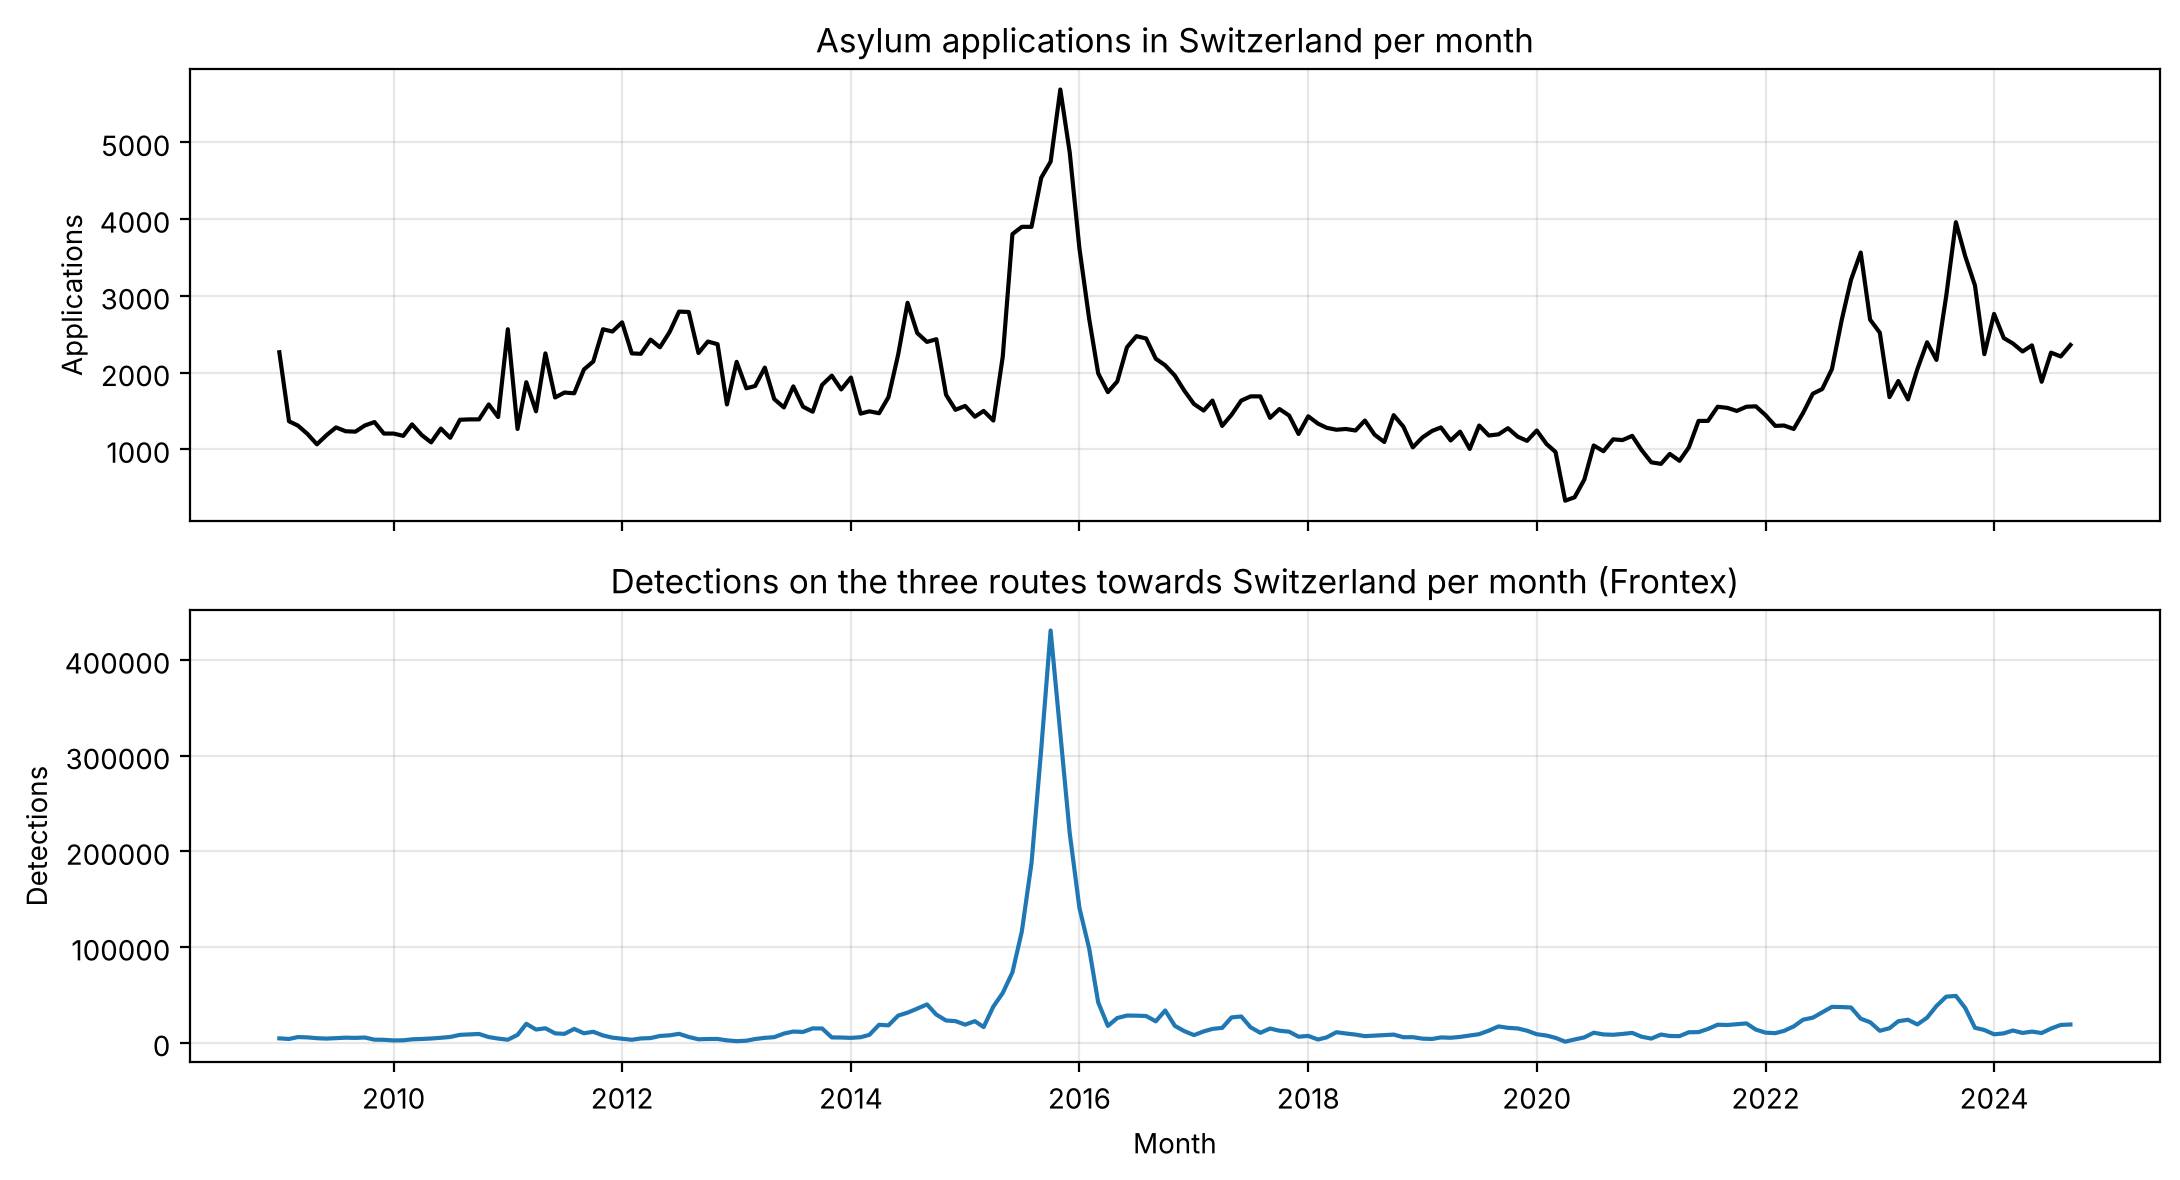

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(both.index, both["applicants_total"], color="black")
axes[0].set_title("Asylum applications in Switzerland per month")
axes[0].set_ylabel("Applications")
axes[1].plot(both.index, both["routes_to_switzerland"], color="tab:blue")
axes[1].set_title("Detections on the three routes towards Switzerland per month (Frontex)")
axes[1].set_ylabel("Detections")
axes[1].set_xlabel("Month")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01b_routes_and_applications.png")
plt.show()

In [8]:
# The highest months of the indicator (sort_values, notebook 02)
print(both["routes_to_switzerland"].sort_values(ascending=False).head(3))

month
2015-10-01    430879
2015-11-01    322656
2015-09-01    306699
Name: routes_to_switzerland, dtype: int64


**What we see.** The indicator is dominated by one huge peak: the three highest months are September to November 2015, with a maximum of 430,879 detections in October 2015, at about the same time as the highest months of applications in Switzerland (upper panel). Smaller rises appear on both panels in 2022 and 2023. Because the 2015 peak is so large, we work with the logarithm of the detections, as for the target.

### Do changes on the routes come before changes in Switzerland?

Notebook 200 showed that two trending series can look strongly correlated without any link (spurious correlation), and that differencing removes this. So we compare **monthly changes** of the logs, not the levels: the correlation between the change of applications in month $s$ and the change of detections $k$ months earlier, for $k = 0, \dots, 6$, with `np.corrcoef` (notebook 200).

This is a **description**, not a choice: the lag the indicator gets in step D is fixed by what is known at the cutoff (section 4), not by this table.

In [9]:
d_apps = np.diff(both["log_applicants"].to_numpy())     # change of log applications, month by month
d_routes = np.diff(both["log_routes"].to_numpy())        # change of log detections, month by month

def lagged_corr(k):
    # Correlation between the change of applications in month s and the change of detections in month s - k
    if k == 0:
        return np.corrcoef(d_apps, d_routes)[0, 1]
    return np.corrcoef(d_apps[k:], d_routes[:-k])[0, 1]

lag_table = pd.DataFrame({"correlation": [round(lagged_corr(k), 2) for k in range(7)]},
                         index=pd.Index(range(7), name="detections k months earlier"))
lag_table

,correlation
detections k months earlier,
0,0.31
1,0.35
2,0.08
3,0.07
4,-0.02
5,-0.08
6,-0.12


**What we see.** The change of applications in Switzerland is correlated with the change of detections in the same month (0.31) and one month earlier (0.35). With detections two or more months earlier, the correlation is close to zero (0.08 at $k = 2$, 0.07 at $k = 3$, and between −0.12 and −0.02 for $k = 4$ to $6$).

**What this means for us.** Movements on the routes show up in Switzerland almost at once, within about a month. But at the cutoff, the newest detection month we know is $t-1$, while the first month we forecast is $t+1$: the gap is at least two months, exactly where the correlation is close to zero. So we expect the indicator to add **little** to our forecasts. We still test it in step D, as planned, because only the backtest can tell; and if it does not help, that is an honest result: the information arrives too late for SEM's decision.

## 6. Save the clean indicator

We keep the month, the three routes, their sum and its logarithm (each value transformed on its own, so nothing leaks from the test period; notebook 209, Step 2).

In [10]:
routes["log_routes"] = np.log(routes["routes_to_switzerland"])
routes_clean = routes[three_routes + ["routes_to_switzerland", "log_routes"]].reset_index()
routes_clean.to_csv("../data/processed/routes_clean.csv", index=False)
print("Saved", routes_clean.shape[0], "months and the columns", list(routes_clean.columns))

Saved 213 months and the columns ['month', 'central_mediterranean', 'eastern_mediterranean', 'western_balkan', 'routes_to_switzerland', 'log_routes']


## 7. A second indicator: applications in the neighbouring countries

People who come to Switzerland often travel through, or first apply in, Germany, Austria, France or Italy. We take the **same Eurostat dataset and the same filters as our target** (`migr_asyappctzm`, all citizenships, applicant type TOTAL) for these four countries, and Switzerland again as a check. The file is Eurostat's SDMX-CSV format: one row per country and month.

In [11]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")
months = clean.index
mkey = months.strftime("%Y-%m")          # months as text, e.g. "2015-09", to match the raw file
TEST_START = pd.Timestamp("2024-10-01")

nb_raw = pd.read_csv("../data/raw/estat_migr_asyappctzm_neighbours_en.csv")
print("Rows:", nb_raw.shape[0], "| countries:", sorted(nb_raw["geo"].unique()),
      "| applicant:", nb_raw["applicant"].unique(), "| last update:", nb_raw["LAST UPDATE"].iloc[0])
print("Flags:")
print(nb_raw.loc[nb_raw["OBS_FLAG"].notna(), ["geo", "TIME_PERIOD", "OBS_VALUE", "OBS_FLAG"]].to_string(index=False))

neighbours = nb_raw.pivot(index="TIME_PERIOD", columns="geo", values="OBS_VALUE").reindex(mkey)
neighbours.index = months
same = (neighbours["CH"] == clean["applicants_total"]).sum()
print()
print("Switzerland identical to our target in", same, "of", len(months), "months")
print("Missing months per country:")
print(neighbours[["DE", "AT", "FR", "IT"]].isna().sum().to_string())

Rows: 1124 | countries: ['AT', 'CH', 'DE', 'FR', 'IT'] | applicant: <StringArray>
['TOTAL']
Length: 1, dtype: str | last update: 18/11/26 11:00:00
Flags:
geo TIME_PERIOD  OBS_VALUE OBS_FLAG
 IT     2026-07       5165        b

Switzerland identical to our target in 225 of 225 months
Missing months per country:
geo
DE    1
AT    0
FR    0
IT    0


**What we see.** The file has 1,124 rows: five countries, January 2008 to September 2026, all with applicant type TOTAL (the same definition as our target), Eurostat update of 18 November 2026. **Switzerland is identical to our target in all 225 months**, so the two downloads are consistent. Germany is missing September 2026, and Italy has a break in series (flag `b`) in July 2026, when the new EU asylum rules started. Both are in the test period, which this step does not use.

## 8. What is known at the cutoff, and the series we keep

Eurostat publishes a month about six weeks after its end (Switzerland's September 2026 appeared on 13 November). At the cutoff around the 15th of month $m$, the forecast origin is $t = m-1$, so the newest neighbour month we may use is **$t-1$**, the same as for the routes.

We keep one series, the sum of the four countries, as a **log** (counts, never zero); the changes are built in the estimation notebook. `min_count=4` leaves a month empty unless all four countries are known, so a missing country never looks like a fall.

In [12]:
neighbours_clean = pd.DataFrame(index=months)
neighbours_clean["log_neighbours"] = np.log(neighbours[["DE", "AT", "FR", "IT"]].sum(axis=1, min_count=4))
neighbours_clean.index.name = "month"
print(neighbours_clean.describe().round(2))
print("Missing:", neighbours_clean["log_neighbours"].isna().sum(), "month(s):",
      list(neighbours_clean.index[neighbours_clean["log_neighbours"].isna()].strftime("%Y-%m")))

       log_neighbours
count          224.00
mean            10.21
std              0.68
min              8.87
25%              9.61
50%             10.36
75%             10.67
max             11.67
Missing: 1 month(s): ['2026-09']


## 9. Explore the indicator next to the target, before the test period

As for the routes (section 5), we look only at the months before the test period: do the monthly changes in the neighbouring countries move together with the Swiss change in the same month, or in the following months (a lead)? We correlate the change in month $s$ with the change of Swiss log applications in month $s + k$.

k (months later)     0     1     2     3
correlation       0.59  0.05 -0.04 -0.07


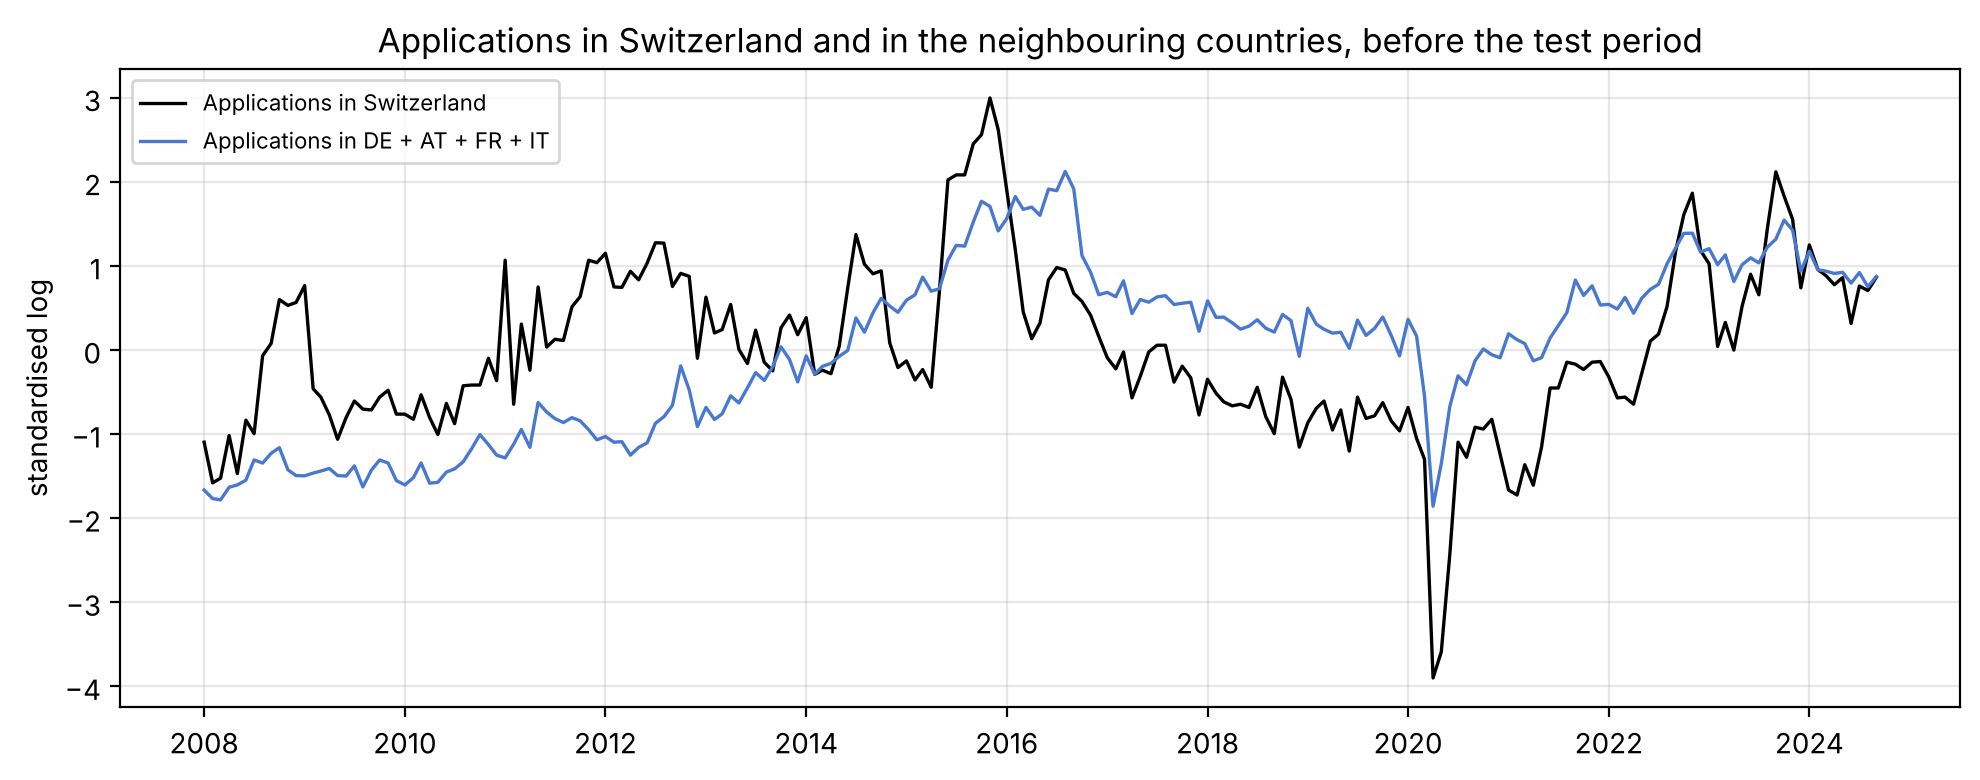

In [13]:
log_y = clean["log_applicants"]
rows = []
for k in range(4):
    both = pd.DataFrame({"ind": neighbours_clean["log_neighbours"].diff(), "app": log_y.diff().shift(-k)})
    both = both[both.index < TEST_START - pd.DateOffset(months=k)].dropna()
    rows.append({"k (months later)": k, "correlation": round(both["ind"].corr(both["app"]), 2)})
print(pd.DataFrame(rows).set_index("k (months later)").T)

before = months < TEST_START
a = (log_y - log_y[before].mean()) / log_y[before].std()
s = neighbours_clean["log_neighbours"]
z = (s - s[before].mean()) / s[before].std()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(months[before], a[before], color="black", lw=1.2, label="Applications in Switzerland")
ax.plot(months[before], z[before], lw=1.2, label="Applications in DE + AT + FR + IT")
ax.set_ylabel("standardised log")
ax.set_title("Applications in Switzerland and in the neighbouring countries, before the test period")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01b_neighbours_and_applications.png")
plt.show()

**What we see.** The change of applications in Germany, Austria, France and Italy moves strongly with the Swiss change **in the same month** (correlation 0.59), but not with the following months (0.05, −0.04, −0.07). In the figure, the two series follow the same big swings: 2015-16, the drop of 2020 and the rise of 2022-23.

**What this means for us.** The neighbouring countries tell us what happens in Switzerland in the same month, and that is the month we cannot use: at the cutoff we know them only up to $t-1$, while we already know Switzerland up to $t$. As for the routes, we expect them to add little two months ahead; only the backtest can tell (`02c`).

## 10. Save the clean series

In [14]:
neighbours_clean.to_csv("../data/processed/neighbours_clean.csv")
print("Saved", neighbours_clean.shape[0], "months and the columns", list(neighbours_clean.columns))

Saved 225 months and the columns ['log_neighbours']


## 11. A third indicator: conflicts in the countries of origin

Wars and violence in the countries people come from may push applications up some months later. We build a conflict index from two inputs: **which nationalities** came to Switzerland recently (this section) and **how violent the news from those countries are** (section 12).

The same Eurostat dataset again, Switzerland, every citizenship. Eurostat writes Namibia as `NA`, so we read the file with `keep_default_na=False`; otherwise pandas would turn Namibia into a missing value.

In [15]:
nat_raw = pd.read_csv("../data/raw/estat_migr_asyappctzm_ch_by_citizenship_en.csv", keep_default_na=False, na_values=[""])
nat = nat_raw.pivot_table(index="TIME_PERIOD", columns="citizen", values="OBS_VALUE", aggfunc="sum").reindex(mkey)
nat.index = months
iso = [c for c in nat.columns if len(c) == 2]          # country codes; the others are groups (EU27_2020, TOTAL, ...)
print("Citizenships:", len(iso), "| TOTAL identical to our target in",
      (nat["TOTAL"] == clean["applicants_total"]).sum(), "of", len(months), "months")

before_test = nat.index < TEST_START
top = (nat.loc[before_test, iso].sum() / nat.loc[before_test, "TOTAL"].sum()).sort_values(ascending=False)
print("Largest shares of all applications, 2008-01 to 2024-09:")
(100 * top.head(10)).round(1)

Citizenships: 199 | TOTAL identical to our target in 225 of 225 months
Largest shares of all applications, 2008-01 to 2024-09:


citizen
ER    15.8
AF    13.1
SY     7.2
TR     7.1
NG     4.6
LK     4.0
DZ     3.6
SO     3.6
IQ     3.5
TN     3.0
dtype: float64

**The weights must be known at the cutoff.** For a forecast origin $t$ we use the share of each nationality in the applications of the 12 months $t-11, \dots, t$, which are all known at the cutoff. The project plan had fixed five origin groups chosen today, which uses hindsight (Johannes' feedback); here the 10 largest groups are chosen again at every origin, from the past 12 months only.

*Not seen in class:* `rolling(12).sum()` adds the current row and the 11 rows before it.

In [16]:
window = nat[iso].rolling(12).sum()
shares = window.div(nat["TOTAL"].rolling(12).sum(), axis=0)      # row t: shares over t-11 ... t
ever_top = sorted(set().union(*[set(shares.loc[m].nlargest(10).index) for m in shares.index[11:]]))
print("Nationalities that are in the top 10 at some origin:", len(ever_top))
print(ever_top)
for m in ["2012-12-01", "2015-09-01", "2021-09-01", "2024-09-01"]:
    t10 = shares.loc[m].nlargest(10)
    print(m[:7], "| top 10 cover", f"{t10.sum():.0%}", "|", ", ".join(f"{c} {v:.0%}" for c, v in t10.head(5).items()))

Nationalities that are in the top 10 at some origin: 22
['AF', 'BI', 'CN', 'DZ', 'ER', 'ET', 'GE', 'GM', 'GN', 'IQ', 'IR', 'LK', 'MA', 'MK', 'NG', 'RS', 'RU', 'SO', 'SY', 'TN', 'TR', 'XK']
2012-12 | top 10 cover 61% | ER 15%, NG 10%, TN 8%, RS 7%, AF 5%
2015-09 | top 10 cover 74% | ER 34%, SY 10%, AF 7%, LK 5%, SO 4%
2021-09 | top 10 cover 80% | AF 19%, ER 15%, TR 15%, SY 7%, DZ 7%
2024-09 | top 10 cover 80% | AF 32%, TR 17%, ER 7%, DZ 7%, SY 5%


**What we see.** The file has 199 citizenships, and its TOTAL is identical to our target in all 225 months. Over 2008 to 2024-09, Eritrea (15.8% of all applications), Afghanistan (13.1%), Syria (7.2%) and Turkey (7.1%) are the largest groups, followed by Nigeria, Sri Lanka, Algeria, Somalia, Iraq and Tunisia (3.0% to 4.6%). The mix changes a lot: at the end of 2012 Nigeria (10%), Tunisia and Serbia were large; in 2015 Eritrea alone was 34%; in 2024 Afghanistan was 32% and Turkey 17%. In total 22 nationalities are in the top 10 at some origin, and the top 10 cover 61% to 80% of all applications.

## 12. Violent events in the news (GDELT)

The GDELT Project codes events from news reports worldwide, every day since 1979, with a fixed scheme (CAMEO): who did what to whom, and where. We downloaded one table with a free query on Google BigQuery (the query is in `../data/raw/SOURCES.md`): for every country where events took place and every month from 2006, the number of all events and of **violent events** (CAMEO root codes 18 *assault*, 19 *fight* and 20 *mass violence*).

**Known at the cutoff?** Yes: GDELT adds new events every day and does not revise old months, so at the cutoff around the 15th of month $m$ the whole month $t = m-1$ is known. November 2026 was still running when we downloaded the file, so we drop it.

**Share, not count.** The number of news events grows a lot over time (GDELT reads more sources each year), so a count would mostly measure the news volume. We use the **share of violent events** among all events in a country and month.

In [17]:
gdelt = pd.read_csv("../data/raw/gdelt_events_by_country_month.csv")
gdelt["month"] = pd.to_datetime(gdelt["month"].astype(str), format="%Y%m")
gdelt = gdelt[gdelt["month"] <= pd.Timestamp("2026-10-01")]           # November 2026 incomplete at download
print("Rows:", len(gdelt), "| countries:", gdelt["country"].nunique(), "| months:",
      gdelt["month"].min().strftime("%Y-%m"), "to", gdelt["month"].max().strftime("%Y-%m"))
total = gdelt.groupby("month")["events_all"].sum()
print("All events per month (thousands):", (total.loc[["2006-01", "2010-01", "2015-01", "2020-01", "2025-01"]] / 1000).round().astype(int).to_dict())

Rows: 61743 | countries: 266 | months: 2006-01 to 2026-10
All events per month (thousands): {Timestamp('2006-01-01 00:00:00'): 315, Timestamp('2010-01-01 00:00:00'): 2235, Timestamp('2015-01-01 00:00:00'): 4383, Timestamp('2020-01-01 00:00:00'): 4054, Timestamp('2025-01-01 00:00:00'): 3567}


GDELT uses FIPS country codes, Eurostat ISO codes (Iraq is `IZ` in FIPS, Turkey `TU`, Nigeria `NI`, ...). We match every nationality that is ever in the top 10.

In [18]:
ISO_TO_FIPS = {"AF": "AF", "BI": "BY", "CN": "CH", "DZ": "AG", "ER": "ER", "ET": "ET", "GE": "GG", "GM": "GA",
               "GN": "GV", "IQ": "IZ", "IR": "IR", "LK": "CE", "MA": "MO", "MK": "MK", "NG": "NI", "RS": "RI",
               "RU": "RS", "SO": "SO", "SY": "SY", "TN": "TS", "TR": "TU", "XK": "KV"}
assert set(ever_top) <= set(ISO_TO_FIPS), set(ever_top) - set(ISO_TO_FIPS)

grid = pd.date_range("2006-01-01", "2026-10-01", freq="MS")
intensity = pd.DataFrame(index=grid)
for c in ever_top:
    one = gdelt[gdelt["country"] == ISO_TO_FIPS[c]].set_index("month").reindex(grid)
    intensity[c] = one["events_violent"] / one["events_all"]        # share of violent events
print("Missing values:", int(intensity.isna().sum().sum()), "| smallest number of events in a country-month:",
      int(min(gdelt[gdelt["country"] == ISO_TO_FIPS[c]]["events_all"].min() for c in ever_top)))
print("Share of violent events, yearly average (%):")
(100 * intensity[["AF", "SY", "ER", "TR", "IQ", "NG"]].groupby(intensity.index.year).mean()).loc[2008:2026].round(0).T

Missing values: 0 | smallest number of events in a country-month: 56
Share of violent events, yearly average (%):


,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
AF,24.0,20.0,22.0,24.0,21.0,18.0,19.0,20.0,20.0,20.0,21.0,18.0,17.0,13.0,12.0,10.0,11.0,10.0,15.0
SY,8.0,4.0,5.0,14.0,20.0,18.0,22.0,21.0,20.0,20.0,19.0,17.0,18.0,16.0,17.0,17.0,22.0,14.0,12.0
ER,8.0,7.0,9.0,6.0,10.0,6.0,8.0,10.0,9.0,7.0,5.0,6.0,10.0,14.0,12.0,10.0,8.0,7.0,7.0
TR,10.0,5.0,7.0,9.0,10.0,8.0,9.0,13.0,13.0,8.0,9.0,9.0,8.0,7.0,7.0,6.0,7.0,6.0,6.0
IQ,17.0,16.0,18.0,17.0,16.0,24.0,24.0,21.0,22.0,19.0,16.0,15.0,17.0,16.0,17.0,15.0,18.0,12.0,14.0
NG,9.0,7.0,7.0,9.0,12.0,10.0,11.0,9.0,8.0,7.0,8.0,8.0,9.0,11.0,8.0,7.0,7.0,8.0,8.0


**What we see.** The file has 266 countries and every month from 2006-01 to 2026-10; every nationality of our list has events in every month (at least 56), so no share is missing. The number of all events grows from 315,000 a month in 2006 to about 4 million in 2015 and stays there: this is why we use shares. The shares follow the known history: **Syria** jumps from 4% to 5% violent events in 2009-10 to 14% in 2011 and about 20% from 2012 (civil war); **Afghanistan** falls from about 20% to 10% to 12% after 2021 (end of the war); **Eritrea** rises to 14% in 2021 (war in neighbouring Tigray). Unlike the UCDP deaths, GDELT also sees Eritrea (6% to 14%), but it measures news about violence, not violence itself, so media attention matters.

## 13. What is known at the cutoff, and the index

- **Shares of the nationalities:** published with the target, so known up to $t$; the weights of origin $t$ use the 12 months $t-11, \dots, t$.
- **Violent events (GDELT):** coded every day and not revised, so known up to $t$.

The index at origin $t$ is the change of the share of violent events in the 10 largest nationalities of origin $t$, weighted by their shares, over 3 and over 6 months, **ending $L$ months before the origin**:

```latex
\text{conflict}_{t}(L, k) = \sum_{c \in \text{top 10 at } t} w_{c,t}\,\big[V_{c,t-L} - V_{c,t-L-k}\big], \qquad k = 3, 6
```

where $V_{c,m}$ is the share of violent events in country $c$ and month $m$. Violence may take several months to turn into applications in Switzerland, so the lag $L$ (0 to 12 months) is **not fixed here**: `02c` chooses it inside each training window, like the penalty `alpha`. We save the two inputs (shares and violence shares).

## 14. Explore the conflict index next to the target, before the test period

As for the other indicators, only the months before the test period. We correlate the monthly change of the weighted share of violent events (weights of that month) with the change of Swiss log applications $k$ months later, for $k = 0$ to $12$: a lead would show up as a clear correlation at some $k$.

k (months later)    0     1    2     3     4     5     6     7     8     9    10    11    12
correlation       0.14  0.08  0.0 -0.06 -0.09  0.09 -0.13  0.07 -0.06  0.03 -0.0 -0.06  0.05
Noise band (2 / sqrt(n)): 0.15


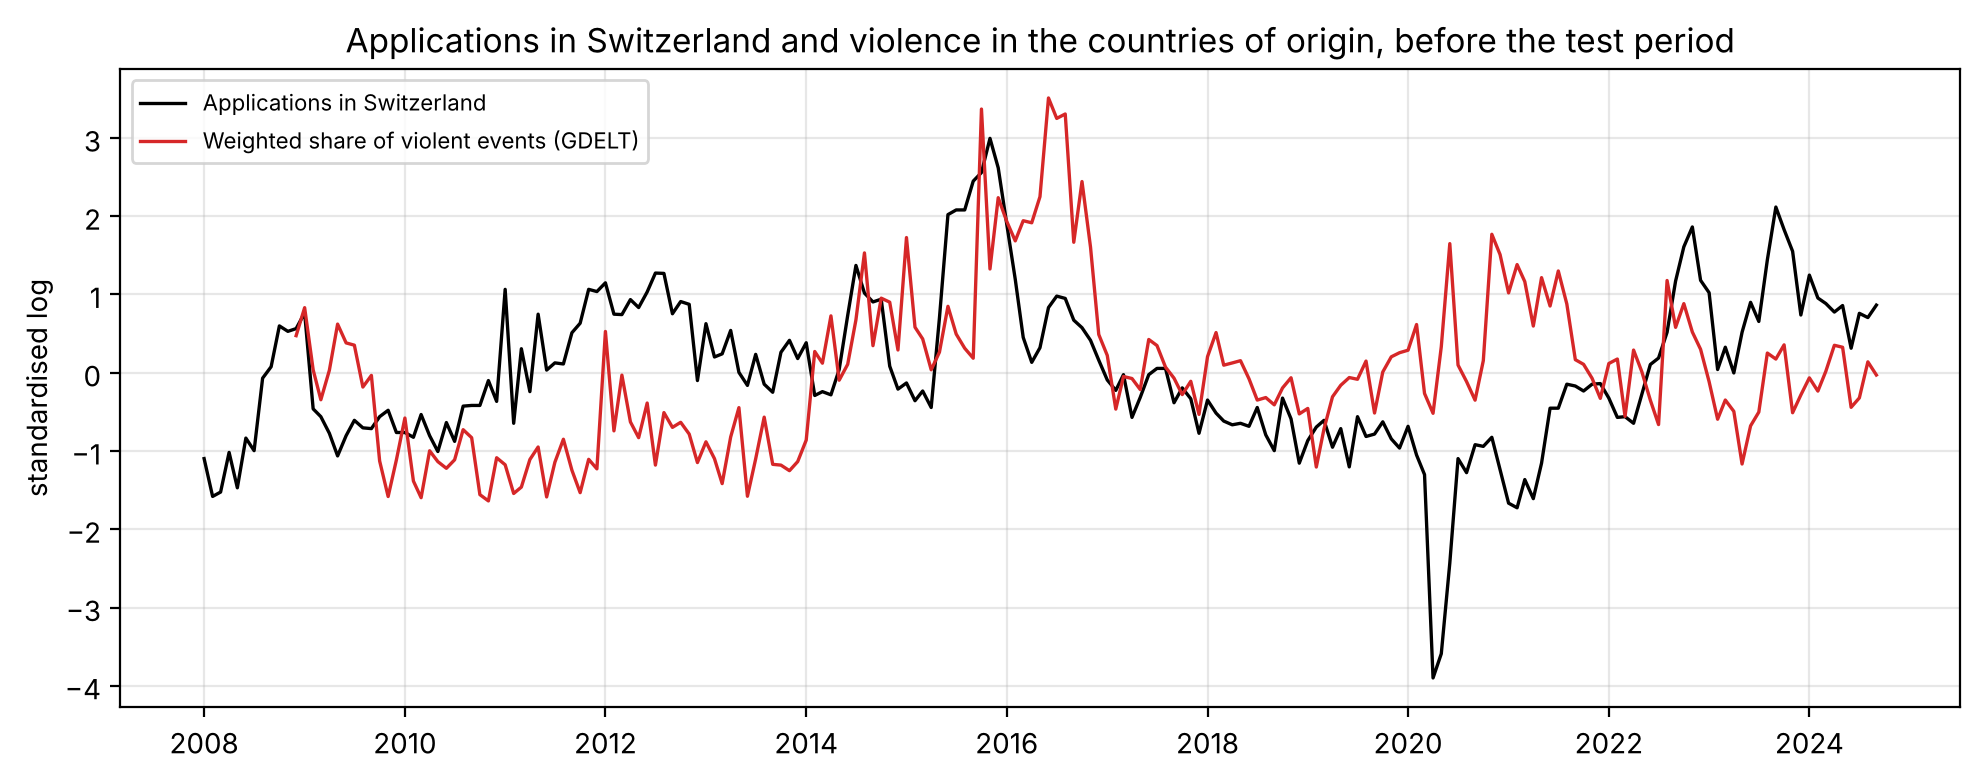

In [19]:
weighted_violence = pd.Series(np.nan, index=months)
for m in months:
    w = shares.loc[m]
    if w.isna().all():
        continue
    t10 = w.nlargest(10)
    weighted_violence[m] = float((t10 * intensity.loc[m, t10.index]).sum())

rows = []
for k in range(13):
    both = pd.DataFrame({"ind": weighted_violence.diff(), "app": log_y.diff().shift(-k)})
    both = both[both.index < TEST_START - pd.DateOffset(months=k)].dropna()
    rows.append({"k (months later)": k, "correlation": round(both["ind"].corr(both["app"]), 2)})
print(pd.DataFrame(rows).set_index("k (months later)").T.to_string())
print("Noise band (2 / sqrt(n)):", round(2 / np.sqrt(len(both)), 2))

z = (weighted_violence - weighted_violence[before].mean()) / weighted_violence[before].std()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(months[before], a[before], color="black", lw=1.2, label="Applications in Switzerland")
ax.plot(months[before], z[before], lw=1.2, color=plt.cm.tab10(3), label="Weighted share of violent events (GDELT)")
ax.set_ylabel("standardised log")
ax.set_title("Applications in Switzerland and violence in the countries of origin, before the test period")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/01b_conflict_and_applications.png")
plt.show()

**What we see.** At every lag from 0 to 12 months, the correlation between the change of the weighted share of violent events and the later Swiss change is small (between −0.13 and +0.14), always inside the noise band of 0.15; the largest is in the same month (0.14).

**What this means for us.** The conflict index shows no clear lead on Swiss applications at any lag. We still test it in `02c`, with the lag chosen inside each training window, because a weak signal could help together with the series' own past.

## 15. Save the conflict inputs

In [20]:
shares_out = shares[ever_top].copy()
shares_out.index.name = "month"
shares_out.to_csv("../data/processed/nationality_shares_clean.csv")
intensity_out = intensity.copy()
intensity_out.index.name = "month"
intensity_out.to_csv("../data/processed/conflict_intensity_clean.csv")
print("Saved:", shares_out.shape, intensity_out.shape)

Saved: (225, 22) (250, 22)


## Summary

**Routes (Frontex)**

- **Data:** Frontex detections by route, 213 months (2009-01 to 2026-09), complete; the three routes towards Switzerland (Central Mediterranean, Eastern Mediterranean, Western Balkan) hold 87% of all detections.
- **Indicator (chosen before looking at the target):** one series, the sum of the three routes, used in logs.
- **Known at the cutoff:** up to month $m-2$, so at a forecast origin $t$ the newest indicator month is $t-1$.
- **First look:** changes on the routes go together with changes in Switzerland in the same month and one month later, but not two or more months later, which is the gap we face at the cutoff.
- **Output:** `../data/processed/routes_clean.csv`.

**Neighbouring countries (Eurostat)**

- **Data:** Eurostat `migr_asyappctzm`, the same dataset and filters as our target, for Germany, Austria, France and Italy, 2008-01 to 2026-09; Switzerland in the same file is identical to our target in 225 of 225 months. Germany misses September 2026, Italy has a break in series in July 2026 (both in the test period).
- **Indicator:** one series, the sum of the four countries, in logs.
- **Known at the cutoff:** up to $t-1$, like the routes.
- **First look:** the change moves with the Swiss change in the same month (0.59), not in the following months (about 0).
- **Not kept:** UNHCR's monthly arrivals (not available in time before 2014 to 2018) and UCDP's conflict deaths (revised final numbers, ending in December 2025).
- **Output:** `../data/processed/neighbours_clean.csv`.

**Conflict index (GDELT and Eurostat)**

- **Data:** Eurostat applications in Switzerland by citizenship (199 citizenships; TOTAL identical to our target in 225 of 225 months) and GDELT events by country and month (266 countries, 2006-01 to 2026-10), from one BigQuery query.
- **Index:** at origin $t$, the change of the share of violent events (CAMEO 18 to 20) in the 10 largest nationalities of the last 12 months, weighted by their shares, over 3 and 6 months, ending $L$ months before the origin; $L$ (0 to 12) is chosen in `02c`.
- **Known at the cutoff:** shares and GDELT both up to $t$; GDELT is not revised.
- **First look:** no clear lead at any lag (all correlations within ±0.14). The shares follow the known wars (Syria from 2011, Afghanistan until 2021, Tigray 2021), but they measure news, not violence.
- **Output:** `nationality_shares_clean.csv` and `conflict_intensity_clean.csv`.